# H6: who are the DCR calibration stars? (internal)

James: are the two colour modes of the DCR calibration stars distinct stellar populations (disk vs halo,
Pop I vs Pop II, turnoff stars vs K/M dwarfs), or a magnitude effect? And does DCR at a fixed colour depend on the
population (spectral differences, e.g. metallicity / alpha enhancement)?
Data: clean Gaia stars with sigma < 10 mas epochs, slices 000, 020, 040, 060 (30% of bricks each).
A. CMD and colour histograms by magnitude and Galactic latitude; B. reduced proper motion H_G = G + 5 log10(mu) + 5
(mu in arcsec/yr) to separate kinematically hot (halo-like) from disk-like stars; C. DCR per unit tan z vs colour for
the two kinematic groups.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u
sys.path.append(os.path.abspath('..'))
from py_files import dcr_fit, plot_style as ps
ps.apply()
OUT = 'plots/'
S = dcr_fit.load_stage_sample(['000', '020', '040', '060'], brick_fraction=0.3)
m = S['clean'] & np.isfinite(S['c_rel']) & np.isfinite(S['bp_rp']) & (S['gaia_pm'] > 0)
# one row per star for the population plots
key = (S['brickid'].astype(np.int64) << 32) | S['objid'].astype(np.int64)
_, first = np.unique(key[m], return_index=True)
st = np.flatnonzero(m)[first]
G, bprp, pm = S['G'][st], S['bp_rp'][st], S['gaia_pm'][st]
b = SkyCoord(S['star_ra'][st] * u.deg, S['star_dec'][st] * u.deg).galactic.b.deg
H = G + 5 * np.log10(pm / 1000.) + 5
print(f"{m.sum():,} epochs of {len(st):,} clean Gaia stars")

4,634,906 epochs of 188,827 clean Gaia stars


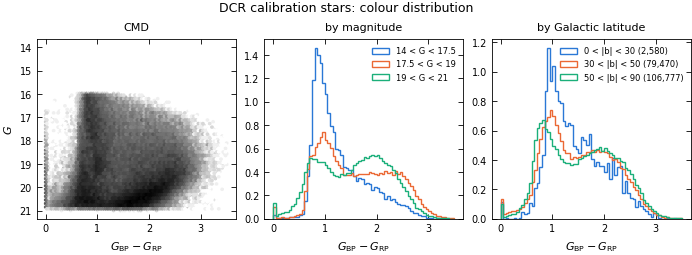

In [2]:
# A. CMD and colour histograms split by magnitude and by Galactic latitude
fig, axes = plt.subplots(1, 3, figsize=(ps.PAGE, 2.6), constrained_layout=True)
axes[0].hexbin(bprp, G, gridsize=80, extent=(0, 3.5, 14, 21), bins='log', cmap=ps.DENSITY, mincnt=1)
axes[0].invert_yaxis(); axes[0].set_xlabel(r'$G_{\rm BP}-G_{\rm RP}$'); axes[0].set_ylabel('$G$'); axes[0].set_title('CMD')
bins = np.linspace(0, 3.5, 71)
for k, (lo, hi) in enumerate([(14, 17.5), (17.5, 19), (19, 21)]):
    s = (G > lo) & (G <= hi)
    axes[1].hist(bprp[s], bins=bins, density=True, histtype='step', color=ps.SERIES[k], label=f'{lo} < G < {hi}')
axes[1].set_xlabel(r'$G_{\rm BP}-G_{\rm RP}$'); axes[1].set_title('by magnitude'); axes[1].legend(fontsize=6)
for k, (lo, hi) in enumerate([(0, 30), (30, 50), (50, 90)]):
    s = (np.abs(b) > lo) & (np.abs(b) <= hi)
    axes[2].hist(bprp[s], bins=bins, density=True, histtype='step', color=ps.SERIES[k], label=f'{lo} < |b| < {hi} ({s.sum():,})')
axes[2].set_xlabel(r'$G_{\rm BP}-G_{\rm RP}$'); axes[2].set_title('by Galactic latitude'); axes[2].legend(fontsize=6)
fig.suptitle('DCR calibration stars: colour distribution')
plt.savefig(OUT + 'h6_cmd_colour_modes.pdf')

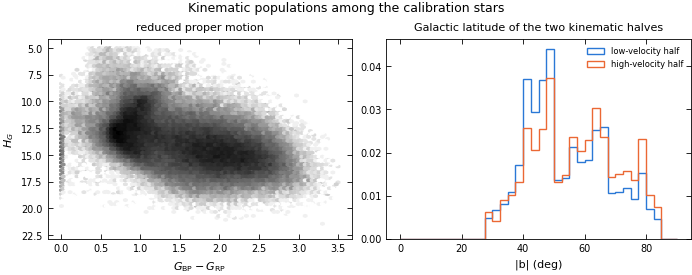

In [3]:
# B. Reduced proper motion: at fixed colour, larger H_G = faster for its brightness (halo-like).
# Split each colour bin at its median H_G into a "high-velocity" and a "low-velocity" half.
cb = np.linspace(0.4, 3.0, 27)
hot = np.zeros(len(st), bool)
for a, c in zip(cb, cb[1:]):
    s = (bprp > a) & (bprp <= c)
    if s.sum() > 50:
        hot[s] = H[s] > np.median(H[s])
fig, axes = plt.subplots(1, 2, figsize=(ps.PAGE, 2.8), constrained_layout=True)
axes[0].hexbin(bprp, H, gridsize=80, extent=(0, 3.5, 5, 22), bins='log', cmap=ps.DENSITY, mincnt=1)
axes[0].invert_yaxis(); axes[0].set_xlabel(r'$G_{\rm BP}-G_{\rm RP}$'); axes[0].set_ylabel('$H_G$'); axes[0].set_title('reduced proper motion')
for k, (s, label) in enumerate([(~hot, 'low-velocity half'), (hot, 'high-velocity half')]):
    axes[1].hist(np.abs(b[s]), bins=np.linspace(0, 90, 37), density=True, histtype='step', color=ps.SERIES[k], label=label)
axes[1].set_xlabel('|b| (deg)'); axes[1].set_title('Galactic latitude of the two kinematic halves'); axes[1].legend(fontsize=6)
fig.suptitle('Kinematic populations among the calibration stars')
plt.savefig(OUT + 'h6_reduced_pm.pdf')

g high - low velocity, offset/tan z per colour bin (mas): {-1.5: 5.3, -1.3: 5.8, -1.1: 1.5, -0.9: -0.3, -0.7: -1.3, -0.5: -1.4, -0.3: -1.8, -0.1: -2.0, 0.1: -2.5, 0.3: -1.5, 0.5: -1.2, 0.7: -0.6}


r high - low velocity, offset/tan z per colour bin (mas): {-1.5: 2.1, -1.3: 1.4, -1.1: 0.2, -0.9: 0.3, -0.7: -0.1, -0.5: -0.1, -0.3: -0.1, -0.1: 0.2, 0.1: 0.1, 0.3: 0.3, 0.5: -0.2, 0.7: -0.0}


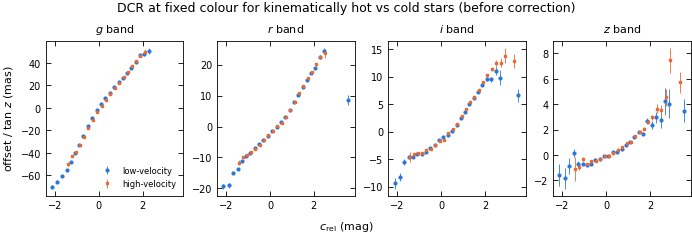

In [4]:
# C. DCR at fixed colour for the two kinematic groups: offset / tan z vs c_rel, tan z > 0.3, raw (before DCR)
hot_star = dict(zip(key[st].tolist(), hot.tolist()))
ep_hot = np.array([hot_star.get(k, False) for k in key.tolist()])
C_EDGES = np.linspace(-2, 3, 26)
fig, axes = plt.subplots(1, 4, figsize=(ps.PAGE, 2.4), sharex=True, constrained_layout=True)
for ax, band in zip(axes, 'griz'):
    for k, (sel, label) in enumerate([(~ep_hot, 'low-velocity'), (ep_hot, 'high-velocity')]):
        q = m & sel & (S['band'] == band) & (S['tanz'] > 0.3) & (S['tanz'] <= 1.3)
        cells = dcr_fit.binned_2d(S['c_rel'][q], S['tanz'][q], S['par_raw'][q], C_EDGES, np.array([0.3, 1.3]), min_count=200)
        cells = cells[:, cells[1] > 0.3]
        ax.errorbar(cells[0] + 0.03 * k, cells[2] / cells[1], cells[3] / cells[1], fmt=ps.MARKERS[k], ms=2, lw=0.6,
                    color=ps.SERIES[k], label=label)
    ax.set_title(f'${band}$ band')
axes[0].set_ylabel('offset / tan $z$ (mas)'); axes[0].legend(fontsize=6)
fig.supxlabel(r'$c_{\rm rel}$ (mag)', fontsize=8)
fig.suptitle('DCR at fixed colour for kinematically hot vs cold stars (before correction)')
plt.savefig(OUT + 'h6_dcr_by_population.pdf')
# quantify: difference between the two groups per colour cell (g band)
for band in 'gr':
    res = {}
    for k, sel in enumerate([~ep_hot, ep_hot]):
        q = m & sel & (S['band'] == band) & (S['tanz'] > 0.3) & (S['tanz'] <= 1.3)
        res[k] = dcr_fit.binned_2d(S['c_rel'][q], S['tanz'][q], S['par_raw'][q], C_EDGES, np.array([0.3, 1.3]), min_count=200)
    a, h = res[0][:, res[0][1] > 0.3], res[1][:, res[1][1] > 0.3]
    common = np.intersect1d(np.round(a[0], 1), np.round(h[0], 1))
    print(band, 'high - low velocity, offset/tan z per colour bin (mas):',
          {c: round(float(h[2][np.round(h[0], 1) == c][0] / h[1][np.round(h[0], 1) == c][0] - a[2][np.round(a[0], 1) == c][0] / a[1][np.round(a[0], 1) == c][0]), 1) for c in common[:12]})